# Lab 4: Simple ANN for Satellite Image Patch Classification (Task 1)

1. `forest.jpg`: A large image containing only forest areas.
2. `urban.jpg`: A large image containing only urban areas.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
import pandas as pd

#set random seeds
np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 1. Posing the Task as a Mathematical Function

An Artificial Neural Network is a universal function approximator. To solve an image classification problem with an ANN, we pose it as finding a mapping function $f$:

$$f: X \rightarrow y$$

* Input ($X$): A 200×200 RGB image patch. Flattened into a 1D vector, each patch is a point in a high-dimensional feature space: $X \in [0, 1]^{200 \times 200 \times 3}$ (120,000 normalized pixel intensity values).
* Output ($y$): A scalar probability $y \in [0, 1]$ representing the likelihood that the patch belongs to the Urban class (where $y < 0.5 \rightarrow$ Forest (0), and $y \ge 0.5 \rightarrow$ Urban (1)).

During training, the ANN adjusts its internal weights and biases to minimize the binary cross-entropy loss between its predicted probabilities $\hat{y} = f(X)$ and the true labels $y$.

## 2. Creating the Training and Testing Data (200×200 Patches)

We load `forest.jpg` and `urban.jpg`, normalize pixel values to $[0, 1]$, and extract 200×200 patches using random cropping (with random horizontal/vertical flips for basic augmentation). We then split the dataset into 80% training and 20% testing.

Training set: (128, 200, 200, 3), Test set: (32, 200, 200, 3)


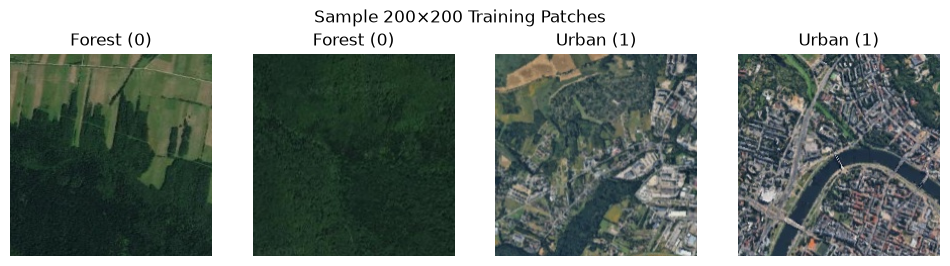

In [ ]:
PATCH_SIZE = 200
PATCHES_PER_CLASS = 80 

def load_image_rgb(path, fallback_color):
    """Loads an RGB image normalized to [0, 1]. Uses synthetic fallback if missing."""
    try:
        img = plt.imread(path)
        if img.dtype == np.uint8:
            img = img.astype(np.float32) / 255.0
        if img.shape[-1] == 4: 
            img = img[..., :3]
        return img
    except FileNotFoundError:
        print(f"Warning: '{path}' not found. Generating synthetic dummy image.")
        noise = np.random.normal(0, 0.1, (600, 600, 3)).astype(np.float32)
        return np.clip(fallback_color + noise, 0.0, 1.0)

def extract_patches(img, num_patches, patch_size=200):
    """Extracts random 200x200 patches with random flips."""
    h, w, _ = img.shape
    if h < patch_size or w < patch_size:
        raise ValueError(f"Image is too small ({h}x{w}) for {patch_size}x{patch_size} patches!")
    
    patches = []
    for _ in range(num_patches):
        y = np.random.randint(0, h - patch_size + 1)
        x = np.random.randint(0, w - patch_size + 1)
        patch = img[y:y+patch_size, x:x+patch_size, :]
        
        #random flips
        if np.random.rand() > 0.5:
            patch = np.fliplr(patch)
        if np.random.rand() > 0.5:
            patch = np.flipud(patch)
        patches.append(patch)
    return np.array(patches, dtype=np.float32)

forest_img = load_image_rgb('forest.jpg', fallback_color=np.array([0.15, 0.35, 0.15]))
urban_img = load_image_rgb('urban.jpg', fallback_color=np.array([0.55, 0.52, 0.50]))

forest_patches = extract_patches(forest_img, PATCHES_PER_CLASS, PATCH_SIZE)
urban_patches = extract_patches(urban_img, PATCHES_PER_CLASS, PATCH_SIZE)

X = np.concatenate([forest_patches, urban_patches], axis=0)
y = np.concatenate([np.zeros(PATCHES_PER_CLASS), np.ones(PATCHES_PER_CLASS)], axis=0)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")

#visualize sample patches
forest_idx = np.where(y_train == 0)[0][:2]
urban_idx = np.where(y_train == 1)[0][:2]
sample_idx = np.concatenate([forest_idx, urban_idx])

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, idx in zip(axes, sample_idx):
    ax.imshow(X_train[idx])
    label_name = 'Urban (1)' if y_train[idx] == 1 else 'Forest (0)'
    ax.set_title(label_name)
    ax.axis('off')
plt.suptitle("Sample 200×200 Training Patches")
plt.show()

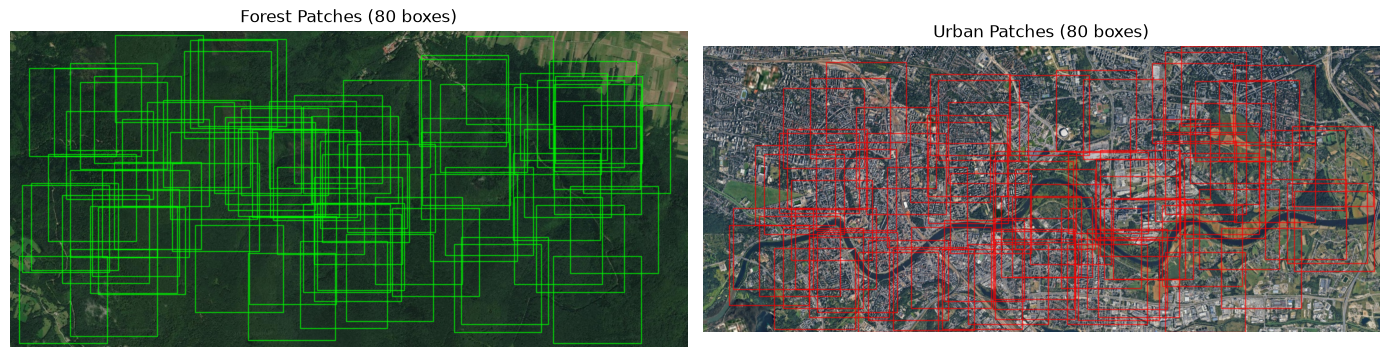

In [9]:
import matplotlib.patches as patches

def extract_patches_with_coords(img, num_patches, patch_size=200):
    h, w, _ = img.shape
    patch_list, coords = [], []
    for _ in range(num_patches):
        y = np.random.randint(0, h - patch_size + 1)
        x = np.random.randint(0, w - patch_size + 1)
        patch = img[y:y+patch_size, x:x+patch_size, :]
        if np.random.rand() > 0.5: patch = np.fliplr(patch)
        if np.random.rand() > 0.5: patch = np.flipud(patch)
        patch_list.append(patch)
        coords.append((x, y))
    return np.array(patch_list, dtype=np.float32), coords

forest_patches, forest_coords = extract_patches_with_coords(forest_img, PATCHES_PER_CLASS, PATCH_SIZE)
urban_patches, urban_coords = extract_patches_with_coords(urban_img, PATCHES_PER_CLASS, PATCH_SIZE)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, img, coords, title, color in [
    (axes[0], forest_img, forest_coords, 'Forest Patches', 'lime'),
    (axes[1], urban_img, urban_coords, 'Urban Patches', 'red')
]:
    ax.imshow(img)
    for (x, y) in coords:
        rect = patches.Rectangle((x, y), PATCH_SIZE, PATCH_SIZE, linewidth=1, edgecolor=color, facecolor='none', alpha=0.6)
        ax.add_patch(rect)
    ax.set_title(f"{title} ({len(coords)} boxes)")
    ax.axis('off')

plt.tight_layout()
plt.show()

## 3. Barebone ANN Architecture

The most minimal (barebone) ANN architecture capable of solving this binary classification problem consists of:
1. Input Layer (`Flatten`): Converts the $200 \times 200 \times 3$ image into a 1D vector of $120,000$ features.
2. Output Layer (`Dense(1, activation='sigmoid')`): A single neuron that computes a weighted sum of all 120,000 inputs and squashes it into a probability $[0, 1]$ via the sigmoid function.

*(Note: This barebone model has no hidden layers—it is mathematically equivalent to logistic regression. Adding hidden layers with non-linear activations like `ReLU` allows the network to learn more complex patterns).* 

## 4 & 5. Running 5 Architecture Permutations

We test 5 different ANN configurations to observe how hidden layers, number of nodes, and optimization algorithms affect performance:
1. **P1 (Barebone):** No hidden layer, `Dense(1, sigmoid)`, Adam (`lr=0.001`)
2. **P2 (1 Hidden Layer - Small):** `Dense(16, relu)` $\rightarrow$ `Dense(1, sigmoid)`, Adam (`lr=0.001`)
3. **P3 (1 Hidden Layer - Wide):** `Dense(64, relu)` $\rightarrow$ `Dense(1, sigmoid)`, Adam (`lr=0.001`)
4. **P4 (2 Hidden Layers - Deep):** `Dense(64, relu)` $\rightarrow$ `Dense(32, relu)` $\rightarrow$ `Dense(1, sigmoid)`, Adam (`lr=0.001`)
5. **P5 (Different Optimizer - SGD):** `Dense(64, relu)` $\rightarrow$ `Dense(32, relu)` $\rightarrow$ `Dense(1, sigmoid)`, SGD (`lr=0.01`)

In [6]:
EPOCHS = 15
BATCH_SIZE = 16
INPUT_SHAPE = (PATCH_SIZE, PATCH_SIZE, 3)

def build_and_run(name, layers, optimizer):
    model = tf.keras.Sequential([tf.keras.layers.Flatten(input_shape=INPUT_SHAPE)] + layers)
    model.compile(
        loss='binary_crossentropy',
        optimizer=optimizer,
        metrics=['accuracy']
    )
    history = model.fit(
        X_train, y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_data=(X_test, y_test),
        verbose=0
    )
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    print(f"{name:30s} | Test Loss: {test_loss:.4f} | Test Acc: {test_acc*100:.2f}% | Params: {model.count_params():,}")
    return {
        'Name': name,
        'Params': model.count_params(),
        'Train Acc (%)': round(history.history['accuracy'][-1] * 100, 2),
        'Test Acc (%)': round(test_acc * 100, 2),
        'Test Loss': round(test_loss, 4),
        'History': history.history
    }

permutations = [
    (
        "P1: Barebone (Adam)",
        [tf.keras.layers.Dense(1, activation='sigmoid')],
        tf.keras.optimizers.Adam(learning_rate=0.001)
    ),
    (
        "P2: 1 Hidden (16, Adam)",
        [tf.keras.layers.Dense(16, activation='relu'),
         tf.keras.layers.Dense(1, activation='sigmoid')],
        tf.keras.optimizers.Adam(learning_rate=0.001)
    ),
    (
        "P3: 1 Hidden (64, Adam)",
        [tf.keras.layers.Dense(64, activation='relu'),
         tf.keras.layers.Dense(1, activation='sigmoid')],
        tf.keras.optimizers.Adam(learning_rate=0.001)
    ),
    (
        "P4: 2 Hidden (64-32, Adam)",
        [tf.keras.layers.Dense(64, activation='relu'),
         tf.keras.layers.Dense(32, activation='relu'),
         tf.keras.layers.Dense(1, activation='sigmoid')],
        tf.keras.optimizers.Adam(learning_rate=0.001)
    ),
    (
        "P5: 2 Hidden (64-32, SGD)",
        [tf.keras.layers.Dense(64, activation='relu'),
         tf.keras.layers.Dense(32, activation='relu'),
         tf.keras.layers.Dense(1, activation='sigmoid')],
        tf.keras.optimizers.SGD(learning_rate=0.01)
    )
]

results = []
for name, layers, opt in permutations:
    results.append(build_and_run(name, layers, opt))

c:\Users\Dell\Desktop\MS2\Machine learning\ML4Space\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


P1: Barebone (Adam)            | Test Loss: 0.0064 | Test Acc: 100.00% | Params: 120,001
P2: 1 Hidden (16, Adam)        | Test Loss: 0.0249 | Test Acc: 96.88% | Params: 1,920,033
P3: 1 Hidden (64, Adam)        | Test Loss: 0.0065 | Test Acc: 100.00% | Params: 7,680,129
P4: 2 Hidden (64-32, Adam)     | Test Loss: 0.0146 | Test Acc: 100.00% | Params: 7,682,177
P5: 2 Hidden (64-32, SGD)      | Test Loss: 0.1998 | Test Acc: 100.00% | Params: 7,682,177


,Name,Params,Train Acc (%),Test Acc (%),Test Loss
0,P1: Barebone (Adam),120001,100.0,100.00,0.0064
1,"P2: 1 Hidden (16, Adam)",1920033,100.0,96.88,0.0249
2,"P3: 1 Hidden (64, Adam)",7680129,100.0,100.00,0.0065
3,"P4: 2 Hidden (64-32, Adam)",7682177,100.0,100.00,0.0146
4,"P5: 2 Hidden (64-32, SGD)",7682177,100.0,100.00,0.1998


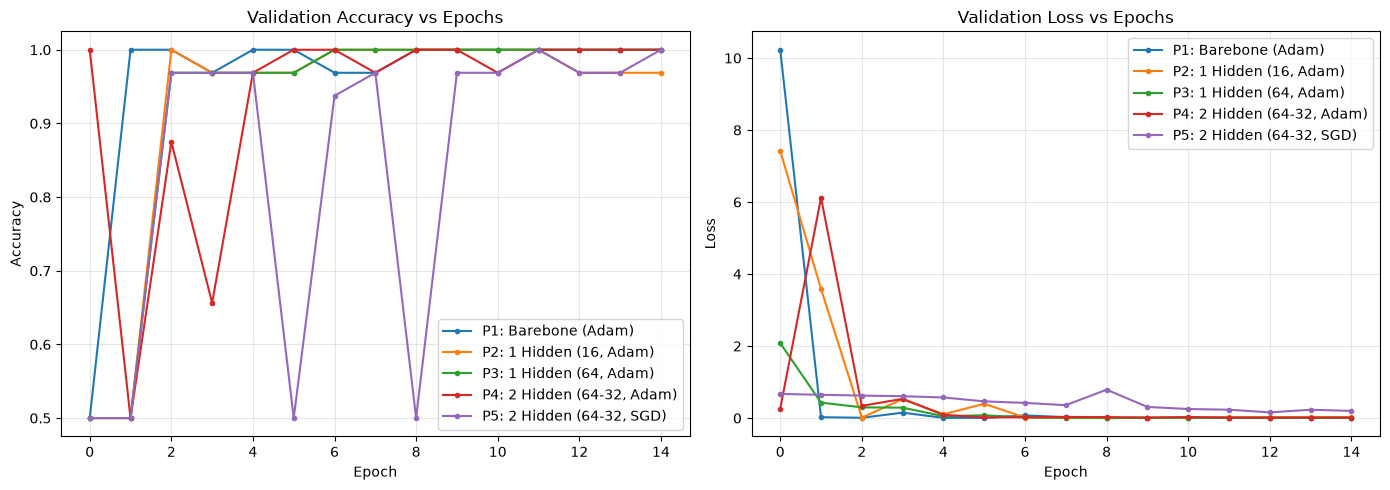

In [ ]:
#summary table
df_results = pd.DataFrame([{k: v for k, v in r.items() if k != 'History'} for r in results])
display(df_results)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for r in results:
    axes[0].plot(r['History']['val_accuracy'], label=r['Name'], marker='o', markersize=3)
    axes[1].plot(r['History']['val_loss'], label=r['Name'], marker='o', markersize=3)

axes[0].set_title('Validation Accuracy vs Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title('Validation Loss vs Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Consolidated Findings & Comparison with Lab 3 (Bayes Classifier)

1. **Dataset & Patch Diversity:** Using large source images (`forest.jpg`: 1552×725 px, `urban.jpg`: 1687×713 px) allowed us to sample diverse 200×200 patches with minimal overlap. Because the test set consists of 32 patches (20% of 160), a single misclassified patch causes an exact accuracy drop of $1/32 \approx 3.1\%$, which explains the discrete steps between `1.00`, `0.97`, and `0.94` on the accuracy plot.
2. **Linear Separability & Parameter Explosion:** Even the barebone model (`P1`, no hidden layers) reached 100% validation accuracy and near-zero loss within 1–2 epochs, showing that forest and urban patches are easily separable by raw color/intensity. Flattening a 200×200×3 patch produces 120,000 input features—meaning a single 64-neuron hidden layer (`P3`) already requires over **7.6 million parameters**, which is computationally heavy and prone to overfitting on small datasets.
3. **Effect of Architecture (Width & Depth):** Among all tested models, `P3` (1 hidden layer, 64 nodes, Adam) showed the smoothest loss curve and held a steady 100% validation accuracy from epoch 6 onward. Adding a second hidden layer (`P4`) introduced more early-epoch instability (a loss spike at epoch 1) without improving final accuracy.
4. **Optimizer Choice (Adam vs. SGD):** Comparing identical architectures (`P4` with Adam vs. `P5` with SGD) highlights a clear advantage for `Adam`. Adam drove validation loss close to zero within a few epochs, whereas standard `SGD` was highly unstable—dropping to 50% accuracy at epochs 5 and 8—and maintained a noticeably higher validation loss (`~0.2–0.8`) throughout training.
5. **ANN vs. Bayesian Classifier (Lab 3):** For straightforward color/intensity separation like forest vs. urban, the **Bayesian classifier** from Lab 3 is far more efficient: it requires estimating only a few parameters (mean and standard deviation), needs minimal data, and is fully interpretable. Dense ANNs are overkill for this task unless working with large datasets and complex spatial features (where Convolutional Neural Networks — CNNs — would be preferred over standard dense layers).
